# Fig. 8: Isotropic NFW benchmark against other codes

This notebook makes Figure 8 of the paper with the scripts that made the arXiv figure, the one of the curves and the one of the figure (the two cells below), unchanged except for the lines that read the package's DF, which here is `pp.compute_df` of ver. 1.0.0 (every changed line marked `[1.0.0]`); galpy and AGAMA run from the arXiv figure's own scripts (`scripts/galpy_iso.py`, `scripts/agama_iso.py`), unchanged apart from their file names, which drop an internal number.

Top panel: $\log_{10}|F_x / F_{\rm PIANISTpy} - 1|$ at $\mathcal{Z} = P_{\rm NFW}(R)$ for [Widrow (2000)](https://doi.org/10.1086/317367), [Lane et al. (2022)](https://doi.org/10.1093/mnras/stab3755), galpy and AGAMA. Bottom panel: $\log_{10}|\varrho / \varrho_{\rm NFW} - 1|$ of the roundtrip (the DF integrated to a density and the Poisson equation solved with $P(0) = 1$) for PIANISTpy, Widrow, Lane et al., and AGAMA's own density. The PIANISTpy curve of the bottom panel sits at the level of the arXiv figure, $10^{-10}$ to $10^{-12}$, with its zero crossings at slightly different $\log_{10} R$, because ver. 1.0.0 computes the DF slightly differently from the paper's code.

Per-call accuracy messages are quieted; the summary lists the model's tier.

In [1]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # before any JAX import: no C++ log lines from XLA

from importlib import metadata

PINS = {"pianistpy": "1.0.0", "numpy": "2.4.3", "scipy": "1.17.1", "galpy": "1.11.0", "agama": "1.0.156"}


def installed(name):
    if name == "pianistpy":  # the module's own version, installed or on the path
        import pianistpy

        return pianistpy.__version__
    if name == "agama":  # its module states the version; its package metadata says 1.0
        try:
            import agama
        except ImportError:
            return None
        return agama.__version__.split()[0]
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return None


found = {name: installed(name) for name in PINS}
for name, pin in PINS.items():
    print(f"{name}: pinned {pin}, installed {found[name]}")


def ready(code):
    """Whether an external code runs: it, numpy and scipy at their pins."""
    off = [f"{n} {found[n] or 'missing'} (pinned {PINS[n]})" for n in (code, "numpy", "scipy") if found[n] != PINS[n]]
    if off:
        print(f"{code} is not run: " + ", ".join(off) + ". Its curve is not drawn.")
    return not off

pianistpy: pinned 1.0.0, installed 1.0.0
numpy: pinned 2.4.3, installed 2.4.3
scipy: pinned 1.17.1, installed 1.17.1
galpy: pinned 1.11.0, installed 1.11.0
agama: pinned 1.0.156, installed 1.0.156


In [2]:
import logging
import math
import warnings

import pianistpy as pp

# The figures of the paper are made with ver. 1.0.0 of the package; any other installed version stops the notebook here.
PIANISTPY_PIN = "1.0.0"
print(f"pianistpy {pp.__version__}")
if pp.__version__ != PIANISTPY_PIN:
    raise RuntimeError(
        f"These figures are made with pianistpy {PIANISTPY_PIN}; the installed version is {pp.__version__}."
    )

# The package reports each result's accuracy twice per call: a line of the pianistpy log and Python's AccuracyWarning.
# set_verbosity("quiet") hides the log's INFO line of a result in the band "recorded"; the pianistpy logger set to
# ERROR also hides the log's WARNING line of a result in the band "warned"; the filter hides the AccuracyWarning.
# The summary after each figure's models prints every model's tier in place of those per-call messages.
pp.set_verbosity("quiet")
logging.getLogger("pianistpy").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=pp.AccuracyWarning)


def tier_line(label, result):
    """One summary line for a result: its label, its report's tier, and the report's worst check with that check's error.

    The worst check is the check of the highest tier level; among checks of one level, the check with the largest error.
    A result whose tier is carried from the Method I model's report, and not from any of the result's own checks, says so.
    """
    if result is None:
        return f"{label:34s} not built: the package's exception is printed above"
    report = result.validation

    def rank(key):
        error = report.checks[key].error
        return (report.checks[key].level, error if not math.isnan(error) else -math.inf)

    worst = max(report.keys, key=rank)
    own_level = report.checks[worst].level
    origin = ", the tier carried from the Method I model's report" if report.parents_level > own_level else ""
    return (f"{label:34s} tier {report.tier:9s} worst check {worst} "
            f"{report.checks[worst].error:.2e}{origin}")


pianistpy 1.0.0


In [3]:
import numpy as np
import pianistpy as pp

df = pp.compute_df(pp.Component(pp.DoublePowerLaw.nfw(), pp.Anisotropy()))
print("Figure 8: the model")
print(tier_line("isotropic NFW, untruncated", df))
print(f"P_0 = {float(df.form.p_0)!r}; table K from {float(df.table.k[0][0]):.3e} to P_0 - {float(df.form.p_0) - float(df.table.k[0][-1]):.6e}, "
      f"{len(df.table.k[0])} nodes")


Figure 8: the model
isotropic NFW, untruncated         tier silent    worst check high_k_slope_mismatch 6.45e-07
P_0 = 1.0; table K from 2.007e-10 to P_0 - 1.001461e-09, 9655 nodes


In [4]:
import subprocess
import sys
import time

# galpy and AGAMA by the scripts of the arXiv figure, unchanged: each writes its table at its own radii
# (galpy 1000 radii 10^-9.9 to 10^9.9, AGAMA 10000 radii 10^-9 to 10^10) into this folder
for code_, script in (("galpy", "scripts/galpy_iso.py"), ("agama", "scripts/agama_iso.py")):
    if not ready(code_):
        continue
    t0 = time.perf_counter()
    r_ = subprocess.run([sys.executable, script], capture_output=True, text=True)
    print(f"{code_}: exit {r_.returncode} in {time.perf_counter() - t0:.0f} s; " + r_.stdout.strip().splitlines()[-1])
    assert r_.returncode == 0, r_.stderr[-2000:]


galpy: exit 0 in 120 s; [Success] Execution complete. Formatted matrix written to: galpy_numerical_iso.txt
agama: exit 0 in 14 s; [Success] Fully self-consistent numerical AGAMA profile dataset written to: agama_numerical_iso.txt


## The curves

About six minutes on one core.

In [5]:
import os
import sys
import time

import numpy as np
from scipy.integrate import solve_ivp
from scipy.interpolate import CubicHermiteSpline, CubicSpline
from scipy.special import roots_legendre

OUT = "fig08_curves.npz"   # [1.0.0] the curves of this run, read by the plot cell below
from pianistpy.df.lookup import evaluate_lookup, prepare_lookup  # noqa: E402  [1.0.0]

T0 = time.perf_counter()
ARR, KINDS = prepare_lookup(df.table, df.form, 0)   # [1.0.0] the package's own lookup of the DF of compute_df
assert float(df.form.p_0) == 1.0, df.form.p_0       # [1.0.0] the curve script's units: P(0) = 1
KTOP = float(df.table.k[0][-1])                     # [1.0.0]
UTOP = 1.0 - KTOP                                   # [1.0.0]
print(f"pianistpy {pp.__version__} compute_df; K_top = 1 - {UTOP:.6e}, {len(df.table.k[0])} nodes from K = {float(df.table.k[0][0]):.3e}", flush=True)


def lgF_pianist(K, uK):
    """log10 F of the DF at (K, u_K = 1 - K), u_K carried exactly near the top."""
    K, uK = np.asarray(K, dtype=np.float64), np.asarray(uK, dtype=np.float64)
    # [1.0.0] the package's lookup, each point given by its depth u_K where the curve script carries u_K exactly (u_K < 0.5), by K elsewhere
    return np.asarray(evaluate_lookup(ARR, KINDS, K, np, u=np.where(uK < 0.5, uK, np.nan)), dtype=np.float64)


def _fit_parts(K, uK):
    Z = np.where(uK < 0.5, 1.0 - uK, K)
    lnZ = np.where(uK < 0.5, np.log1p(-uK), np.log(np.maximum(K, 1e-300)))
    return Z, uK, -lnZ


def lgF_widrow(K, uK):
    Z, E2, mlnZ = _fit_parts(np.asarray(K, float), np.asarray(uK, float))
    q, p1, p2, p3, p4, F0 = -2.7419, 0.3620, -0.5639, -0.0859, -0.4912, 0.091968
    lg = (np.log10(F0) + 1.5 * np.log10(Z) - 2.5 * np.log10(E2) + q * np.log10(mlnZ / E2)
          + (p1 * Z + p2 * Z ** 2 + p3 * Z ** 3 + p4 * Z ** 4) / np.log(10.0))
    return lg


LANE = (0.0926081086527954, 0.0232272797489981, 0.258346829924101, -2.97848277491979, 14.9776586391246, -46.6587221550258,
        92.6397009471828, -117.647787290798, 92.5144063082258, -41.0268009529576, 7.84806318891231)


def lgF_lane(K, uK):
    Z, E2, mlnZ = _fit_parts(np.asarray(K, float), np.asarray(uK, float))
    poly = np.polyval(LANE[::-1], Z)
    return 1.5 * np.log10(Z) - 2.5 * np.log10(E2) - 2.75 * np.log10(mlnZ / E2) + np.log10(poly)


XG, WG = roots_legendre(8)


def _panels(a, b, h):
    n = max(1, int(np.ceil((b - a) / h)))
    e = np.linspace(a, b, n + 1)
    mid, half = 0.5 * (e[1:] + e[:-1]), 0.5 * (e[1:] - e[:-1])
    return (mid[:, None] + half[:, None] * XG[None, :]).ravel(), (half[:, None] * WG[None, :]).ravel()


def integral(lgF, u, h, Pv=None):
    """INT_0^P F(K) sqrt(P - K) dK at P = 1 - u (u exact; P passed as well where it is the exact one, P <= 0.7)."""
    Pv = (1.0 - u) if Pv is None else Pv
    # lower piece: K in [1e-40, P/2] in ln K
    t, wt = _panels(np.log(1e-40), np.log(0.5 * Pv), h)
    K = np.exp(t)
    uK = 1.0 - K
    lo = np.sum(wt * 10.0 ** lgF(K, uK) * np.sqrt(Pv - K) * K)
    # upper piece: w = P - K in [1e-30 P, P/2] in ln w; u_K = u + w exactly enough
    s, ws = _panels(np.log(1e-30 * Pv), np.log(0.5 * Pv), h)
    w = np.exp(s)
    K = Pv - w
    uK = u + w
    up = np.sum(ws * 10.0 ** lgF(K, uK) * np.sqrt(w) * w)
    return lo + up


CFWD = 4.0 * np.pi * np.sqrt(2.0)


def u_of_R(R):
    R = np.asarray(R, dtype=np.float64)
    out = np.empty(R.shape)
    s = R < 0.1
    k = np.arange(1, 30)
    out[s] = np.sum(((-1.0) ** (k + 1))[None, :] * R[s, None] ** k[None, :] / (k + 1.0)[None, :], axis=1)
    out[~s] = 1.0 - np.log1p(R[~s]) / R[~s]
    return out


def P_of_R(R):
    R = np.asarray(R, dtype=np.float64)
    return np.where(R < 0.1, 1.0 - u_of_R(R), np.log1p(R) / R)


def M_of_R(R):
    R = np.asarray(R, dtype=np.float64)
    out = np.empty(R.shape)
    s = R < 0.1
    k = np.arange(2, 32)
    out[s] = np.sum(((-1.0) ** k * (k - 1.0) / k)[None, :] * R[s, None] ** k[None, :], axis=1)
    out[~s] = np.log1p(R[~s]) - R[~s] / (1.0 + R[~s])
    return out


def rho_nfw(R):
    R = np.asarray(R, dtype=np.float64)
    return 1.0 / (R * (1.0 + R) ** 2)


def R_of_u(u):
    """inverse of u_of_R by Newton in ln R (u <= 0.7)."""
    u = np.asarray(u, dtype=np.float64)
    lnR = np.log(2.0 * u)
    k = np.arange(1, 30)
    for _ in range(60):
        R = np.exp(lnR)
        f = np.log(u_of_R(R)) - np.log(u)
        s = R < 0.1
        Rdu = np.empty(R.shape)                                                       # R du/dR, by the series below 0.1
        Rdu[s] = np.sum(((-1.0) ** (k + 1) * k / (k + 1.0))[None, :] * R[s, None] ** k[None, :], axis=1)
        Rdu[~s] = np.log1p(R[~s]) / R[~s] - 1.0 / (1.0 + R[~s])
        d = Rdu / u_of_R(R)                                                           # dln u / dln R
        lnR = lnR - f / d
    return np.exp(lnR)


def R_of_P(Pv):
    Pv = np.asarray(Pv, dtype=np.float64)
    lnR = np.log(np.maximum(-np.log(Pv) / Pv, 2.0))
    for _ in range(80):
        R = np.exp(lnR)
        f = np.log(P_of_R(R)) - np.log(Pv)
        d = R * (1.0 / (R * (1.0 + R)) - np.log1p(R) / R ** 2) / P_of_R(R)                # dln P / dln R
        lnR = lnR - f / d
    return np.exp(lnR)


# ---- the density tables of each source
U_IN = np.logspace(-12, np.log10(0.7), int(400 * (12 + np.log10(0.7))) + 1)
P_OUT = np.logspace(-11, np.log10(0.7), int(1600 * (11 + np.log10(0.7))) + 1)   # 1600 a decade: the outer Poisson floor (h^4) for R to 1e8
H = 0.025


def table(lgF, name):
    t0 = time.perf_counter()
    rin = np.array([CFWD * integral(lgF, u, H) for u in U_IN])
    rout = np.array([CFWD * integral(lgF, 1.0 - p, H, p) for p in P_OUT])
    # quadrature check at panel width 2H on a sample
    js = np.linspace(0, len(U_IN) - 1, 25).astype(int)
    dq_in = max(abs(CFWD * integral(lgF, U_IN[j], 2 * H) / rin[j] - 1.0) for j in js)
    js2 = np.linspace(0, len(P_OUT) - 1, 25).astype(int)
    dq_out = max(abs(CFWD * integral(lgF, 1.0 - P_OUT[j], 2 * H, P_OUT[j]) / rout[j] - 1.0) for j in js2)
    sin = CubicSpline(np.log(U_IN), np.log(rin))
    sout = CubicSpline(np.log(P_OUT), np.log(rout))
    # spline check at midpoints
    um = np.sqrt(U_IN[js[:-1] + 1] * U_IN[js[:-1] + 2])
    ds_in = max(abs(np.exp(sin(np.log(x))) / (CFWD * integral(lgF, x, H)) - 1.0) for x in um)
    pm = np.sqrt(P_OUT[js2[:-1] + 1] * P_OUT[js2[:-1] + 2])
    ds_out = max(abs(np.exp(sout(np.log(x))) / (CFWD * integral(lgF, 1.0 - x, H, x)) - 1.0) for x in pm)
    print(f"{name}: density tables {len(U_IN)} + {len(P_OUT)} nodes in {time.perf_counter() - t0:.0f} s; quadrature H vs 2H "
          f"{dq_in:.1e} (inner), {dq_out:.1e} (outer); spline vs direct at midpoints {ds_in:.1e}, {ds_out:.1e}", flush=True)
    # the closure on the same nodes, c(P) = rho[F](P) / rho_NFW(R_NFW(P)) - 1, for the residual Poisson solve
    cin = CubicSpline(np.log(U_IN), rin / rin_x - 1.0)
    cout = CubicSpline(np.log(P_OUT), rout / rout_x - 1.0)
    # its error budget for the residual solve: the whole table at panel width 2H, and the H table on every other node
    rin2 = np.array([CFWD * integral(lgF, u, 2 * H) for u in U_IN])
    rout2 = np.array([CFWD * integral(lgF, 1.0 - p, 2 * H, p) for p in P_OUT])
    alt = dict(c2H=(CubicSpline(np.log(U_IN), rin2 / rin_x - 1.0), CubicSpline(np.log(P_OUT), rout2 / rout_x - 1.0)),
               chalf=(CubicSpline(np.log(U_IN[::2]), (rin / rin_x - 1.0)[::2]), CubicSpline(np.log(P_OUT[::2]), (rout / rout_x - 1.0)[::2])))
    return rin, rout, sin, sout, dict(dq_in=dq_in, dq_out=dq_out, ds_in=ds_in, ds_out=ds_out), cin, cout, alt


def make_rho(sin, sout, c0):
    def rho_u(u):
        if u < 1e-12:
            return c0 / u
        if u <= 0.5:
            return float(np.exp(sin(np.log(u))))
        return float(np.exp(sout(np.log(1.0 - u))))

    def rho_P(Pv):
        if Pv <= 0.5:
            return float(np.exp(sout(np.log(Pv))))
        return float(np.exp(sin(np.log(1.0 - Pv))))
    return rho_u, rho_P


R0, R_SWITCH, R_END = 1e-10, 1.0, 1e9
LOGR_OUT = np.round(np.arange(-10.0, 9.0 + 1e-9, 0.005), 6)
R_OUT = 10.0 ** LOGR_OUT


def poisson(rho_u, rho_P, c0):
    v0 = np.sqrt(0.5 * c0)
    tin = np.log(R_OUT[R_OUT <= R_SWITCH])
    f1 = lambda t, y: [y[1] - y[0], np.exp(t) * rho_u(y[0] * np.exp(t)) - 2.0 * y[1]]
    s1 = solve_ivp(f1, (min(np.log(R0), tin[0]), max(np.log(R_SWITCH), tin[-1])), [v0, v0], method="DOP853", rtol=1e-13, atol=1e-30, t_eval=tin,
                   dense_output=True)
    vS, mS = s1.sol(np.log(R_SWITCH))
    pS, MS = (1.0 - vS * R_SWITCH) * R_SWITCH, mS * R_SWITCH ** 2
    tout = np.log(R_OUT[R_OUT > R_SWITCH])
    f2 = lambda t, y: [y[0] - y[1], np.exp(3.0 * t) * rho_P(y[0] * np.exp(-t))]
    # a source whose self-consistent potential reaches the table floor P = 1e-11 at a finite radius (a fit with a mass excess
    # outward) ends there: the radii beyond carry no value (NaN), and the radius is printed
    ev = lambda t, y: y[0] * np.exp(-t) - 1e-11
    ev.terminal, ev.direction = True, -1
    s2 = solve_ivp(f2, (np.log(R_SWITCH), max(np.log(R_END), tout[-1])), [pS, MS], method="DOP853", rtol=1e-13, atol=1e-30, t_eval=tout,
                   events=ev)
    if s2.t_events[0].size:
        print(f"  the potential reaches P = 1e-11 at R = {np.exp(s2.t_events[0][0]):.4e}: no value beyond", flush=True)
    u_in = s1.y[0] * np.exp(s1.t)
    P_out = np.full(tout.shape, np.nan)
    P_out[:s2.t.size] = s2.y[0] * np.exp(-s2.t)
    rho = np.concatenate([[rho_u(x) for x in u_in], [rho_P(x) if np.isfinite(x) else np.nan for x in P_out]])
    u_all = np.concatenate([u_in, 1.0 - P_out])
    print(f"  Poisson: {s1.nfev + s2.nfev} evaluations, status {s1.status}/{s2.status}", flush=True)
    return rho, u_all


_KS = np.arange(1, 30)
_US = ((-1.0) ** (_KS + 1) / (_KS + 1.0))[::-1]            # u = sum_k (-1)^(k+1) R^k / (k+1): Horner coefficients, k = 29..1
_DUS = ((-1.0) ** (_KS + 1) * _KS / (_KS + 1.0))[::-1]     # R du/dR = sum_k (-1)^(k+1) k R^k / (k+1)


def _u_s(R):
    return R * np.polyval(_US, R) if R < 0.1 else 1.0 - np.log1p(R) / R


def _Rdu_s(R):
    return R * np.polyval(_DUS, R) if R < 0.1 else np.log1p(R) / R - 1.0 / (1.0 + R)


def _shift(R, d, uN, PN_):
    """eps = ln(R'/R) with P_NFW(R') = P_NFW(R) + d (d = delta), by Newton in the variable that keeps its digits."""
    inner = uN <= 0.5
    if inner:
        tgt = np.log1p(-d / uN)                    # ln(u' / u_N), u' = u_N - d
        f = lambda e: np.log(_u_s(R * np.exp(e)) / uN) - tgt
        g = lambda e: _Rdu_s(R * np.exp(e)) / _u_s(R * np.exp(e))
    else:
        tgt = np.log1p(d / PN_)                    # ln(P' / P_N)
        f = lambda e: np.log((1.0 - _u_s(R * np.exp(e)) if R * np.exp(e) < 0.1 else np.log1p(R * np.exp(e)) / (R * np.exp(e))) / PN_) - tgt
        g = lambda e: -_Rdu_s(R * np.exp(e)) / (1.0 - _u_s(R * np.exp(e)) if R * np.exp(e) < 0.1 else np.log1p(R * np.exp(e)) / (R * np.exp(e)))
    e = tgt / g(0.0)                               # first order: exact to |tgt| relative, and tgt carries its digits (log1p)
    if abs(tgt) < 1e-6:
        return e
    for _ in range(60):                            # large shifts (a fit near its potential's zero): Newton to f's rounding
        de = f(e) / g(e)
        e -= de
        if abs(de) <= 1e-14 * abs(e) + 1e-16:
            break
    return e


def poisson_resid(cin, cout, rtol=1e-12):
    """the roundtrip's Poisson solve as a residual about the analytic NFW potential: P = P_NFW(R) + delta,
    lap delta = -(rho[F](P) - rho_NFW(R)), P(0) = 1 (delta = 0 at the center). The same equation as the outward solve, but P is
    never formed as 1 minus an accumulated integral: delta carries its own digits and float64 holds it. rho[F](P) =
    rho_NFW(R_NFW(P)) (1 + c(P)); the roundtrip error at R is rho[F](P) / rho_NFW(R) - 1 = expm1(D) + c exp(D), D = ln rho_NFW(R')
    - ln rho_NFW(R), R' = R_NFW(P)."""
    def parts(t, d):
        R = np.exp(t)
        uN = _u_s(R)
        PN_ = 1.0 - uN if R < 0.1 else np.log1p(R) / R
        e = _shift(R, d, uN, PN_)
        D = -e - 2.0 * np.log1p(R * np.expm1(e) / (1.0 + R))
        u, Pv = uN - d, PN_ + d
        c = float(cin(np.log(max(u, 1e-12)))) if u <= 0.5 else float(cout(np.log(Pv)))
        return R, np.expm1(D) + c * np.exp(D), Pv

    def f(t, y):
        R, rel, _ = parts(t, y[0])
        return [y[1] / R, -R ** 3 * rho_nfw(R) * rel]

    ev = lambda t, y: parts(t, y[0])[2] - 1e-11
    ev.terminal, ev.direction = True, -1
    s = solve_ivp(f, (np.log(1e-12), max(np.log(R_END), np.log(R_OUT[-1]))), [0.0, 0.0], method="DOP853", rtol=rtol, atol=1e-60,
                  t_eval=np.log(R_OUT), events=ev)
    rt = np.full(R_OUT.shape, np.nan)
    d = np.full(R_OUT.shape, np.nan)
    for i, (t, dd) in enumerate(zip(s.t, s.y[0])):
        rt[i], d[i] = parts(t, dd)[1], dd
    if s.t_events[0].size:
        print(f"  residual solve: the potential reaches P = 1e-11 at R = {np.exp(s.t_events[0][0]):.4e}: zero density beyond", flush=True)
    print(f"  residual Poisson (rtol {rtol:g}): {s.nfev} evaluations, status {s.status}", flush=True)
    return rt, d


res = dict(logR=LOGR_OUT, R=R_OUT)
uN, PN = u_of_R(R_OUT), P_of_R(R_OUT)
rN = rho_nfw(R_OUT)
res["u_nfw"], res["rho_nfw"] = uN, rN

# normalization check: C rho_fwd / rho_NFW at mid radii with the product's F
for Rm in (0.1, 1.0, 10.0):
    um = float(u_of_R(np.array([Rm]))[0])
    print(f"normalization: C INT F sqrt(P - K) dK / rho_NFW at R = {Rm:g}: {CFWD * integral(lgF_pianist, um, H) / rho_nfw(Rm):.12f}",
          flush=True)

# the exact NFW density through the same tables and solver: the machinery's own floor
rin_x = rho_nfw(R_of_u(U_IN))
rout_x = rho_nfw(R_of_P(P_OUT))
print(f"inverse check: u(R(u)) / u - 1 max {np.max(np.abs(u_of_R(R_of_u(U_IN)) / U_IN - 1.0)):.1e}, "
      f"P(R(P)) / P - 1 max {np.max(np.abs(P_of_R(R_of_P(P_OUT)) / P_OUT - 1.0)):.1e}", flush=True)
sin_x, sout_x = CubicSpline(np.log(U_IN), np.log(rin_x)), CubicSpline(np.log(P_OUT), np.log(rout_x))
c0x = U_IN[0] * rin_x[0]
rho_u, rho_P = make_rho(sin_x, sout_x, c0x)
rho, u_rt = poisson(rho_u, rho_P, c0x)
res["exact_rt"] = rho / rN - 1.0
print(f"exact NFW through the tables and the solver: |rt - 1| max {np.max(np.abs(res['exact_rt'])):.2e} "
      f"(R <= 1e5: {np.max(np.abs(res['exact_rt'][R_OUT <= 1e5])):.2e}); c0 = {c0x:.15e} (exact 1/2)", flush=True)

for name, lgF in (("pianist", lgF_pianist), ("widrow", lgF_widrow), ("lane", lgF_lane)):
    rin, rout, sin, sout, chk, cin, cout, alt = table(lgF, name)
    c0 = U_IN[0] * rin[0]
    rho_u, rho_P = make_rho(sin, sout, c0)
    # closure: rho[F](P_NFW(R)) against rho_NFW(R), no Poisson
    clo = np.array([rho_u(x) for x in uN]) / rN - 1.0
    rho, u_rt = poisson(rho_u, rho_P, c0)
    res[f"{name}_rt_outward"], res[f"{name}_u_rt"] = rho / rN - 1.0, u_rt
    rt, dlt = poisson_resid(cin, cout)
    rt2, _ = poisson_resid(cin, cout, rtol=1e-10)
    m3 = R_OUT <= 1e3
    print(f"{name}: residual against outward solve on R <= 1e3: max |diff| {np.nanmax(np.abs(rt[m3] - res[f'{name}_rt_outward'][m3])):.2e}; "
          f"residual at rtol 1e-12 against 1e-10: max |diff| {np.nanmax(np.abs(rt - rt2)):.2e}", flush=True)
    for k, (ci, co) in alt.items():
        rta, _ = poisson_resid(ci, co)
        res[f"{name}_rt_{k}"] = rta
        print(f"{name}: residual with the table {'at 2H' if k == 'c2H' else 'on every other node'}: max |diff| " +
              ", ".join(f"R <= 1e{L}: {np.nanmax(np.abs((rta - rt)[R_OUT <= 10.0 ** L])):.2e}" for L in (0, 3, 5, 7, 8, 9)), flush=True)
    res[f"{name}_closure"], res[f"{name}_rt"], res[f"{name}_delta"] = clo, rt, dlt
    res[f"{name}_c0"] = c0
    for k, v in chk.items():
        res[f"{name}_{k}"] = v
    res[f"{name}_F_at_Pnfw"] = 10.0 ** lgF(PN, uN)
    print(f"{name}: c0 u rho at u = 1e-12: {c0:.12e} (exact 1/2); roundtrip at log R = -10, -9, "
          f"-8, -6, -4, -2, 0, 2, 4: " + ", ".join(f"{rt[np.argmin(abs(LOGR_OUT - L))]:+.2e}" for L in (-10, -9, -8, -6, -4, -2, 0, 2, 4)),
          flush=True)

# the DF on the product's own nodes and at the table top, for the record
res["pianist_K_nodes"] = np.asarray(df.table.k[0])        # [1.0.0]
res["pianist_lg_nodes"] = np.asarray(df.table.log_df[0])  # [1.0.0]
res["u_top"] = UTOP
res["data_sha256"] = f"pianistpy {pp.__version__} compute_df"   # [1.0.0] no stored file
np.savez(OUT, **res)
print(f"wrote {OUT} in {time.perf_counter() - T0:.0f} s", flush=True)


pianistpy 1.0.0 compute_df; K_top = 1 - 1.001461e-09, 9655 nodes from K = 2.007e-10
normalization: C INT F sqrt(P - K) dK / rho_NFW at R = 0.1: 0.999999999998
normalization: C INT F sqrt(P - K) dK / rho_NFW at R = 1: 1.000000000000
normalization: C INT F sqrt(P - K) dK / rho_NFW at R = 10: 1.000000000000
inverse check: u(R(u)) / u - 1 max 3.9e-15, P(R(P)) / P - 1 max 3.6e-15
  Poisson: 2602 evaluations, status 0/0
exact NFW through the tables and the solver: |rt - 1| max 7.67e-07 (R <= 1e5: 4.04e-09); c0 = 4.999999999973325e-01 (exact 1/2)
pianist: density tables 4739 + 17353 nodes in 57 s; quadrature H vs 2H 1.1e-11 (inner), 3.0e-10 (outer); spline vs direct at midpoints 1.5e-11, 5.8e-12
  Poisson: 4246 evaluations, status 0/0
  residual Poisson (rtol 1e-12): 781937 evaluations, status 0
  residual Poisson (rtol 1e-10): 373298 evaluations, status 0
pianist: residual against outward solve on R <= 1e3: max |diff| 2.08e-10; residual at rtol 1e-12 against 1e-10: max |diff| 6.92e-16
  resi

## The figure

printed scale s = 0.4119 (f 1.0, slot column, W_fig 590.2 pt)
NFW_Benchmark_Iso_chop.png: x [-8, 8]
  PIANISTpy rt: log10|delta| over [-14.49, -8.87] (axis [-14.5, 1.0])
  Widrow rt: log10|delta| over [-7.51, -0.00] (axis [-14.5, 1.0])
  Lane rt: log10|delta| over [-7.34, 1.00] (axis [-14.5, 1.0])
  agama rho: log10|delta| over [-8.58, -0.53] (axis [-14.5, 1.0])


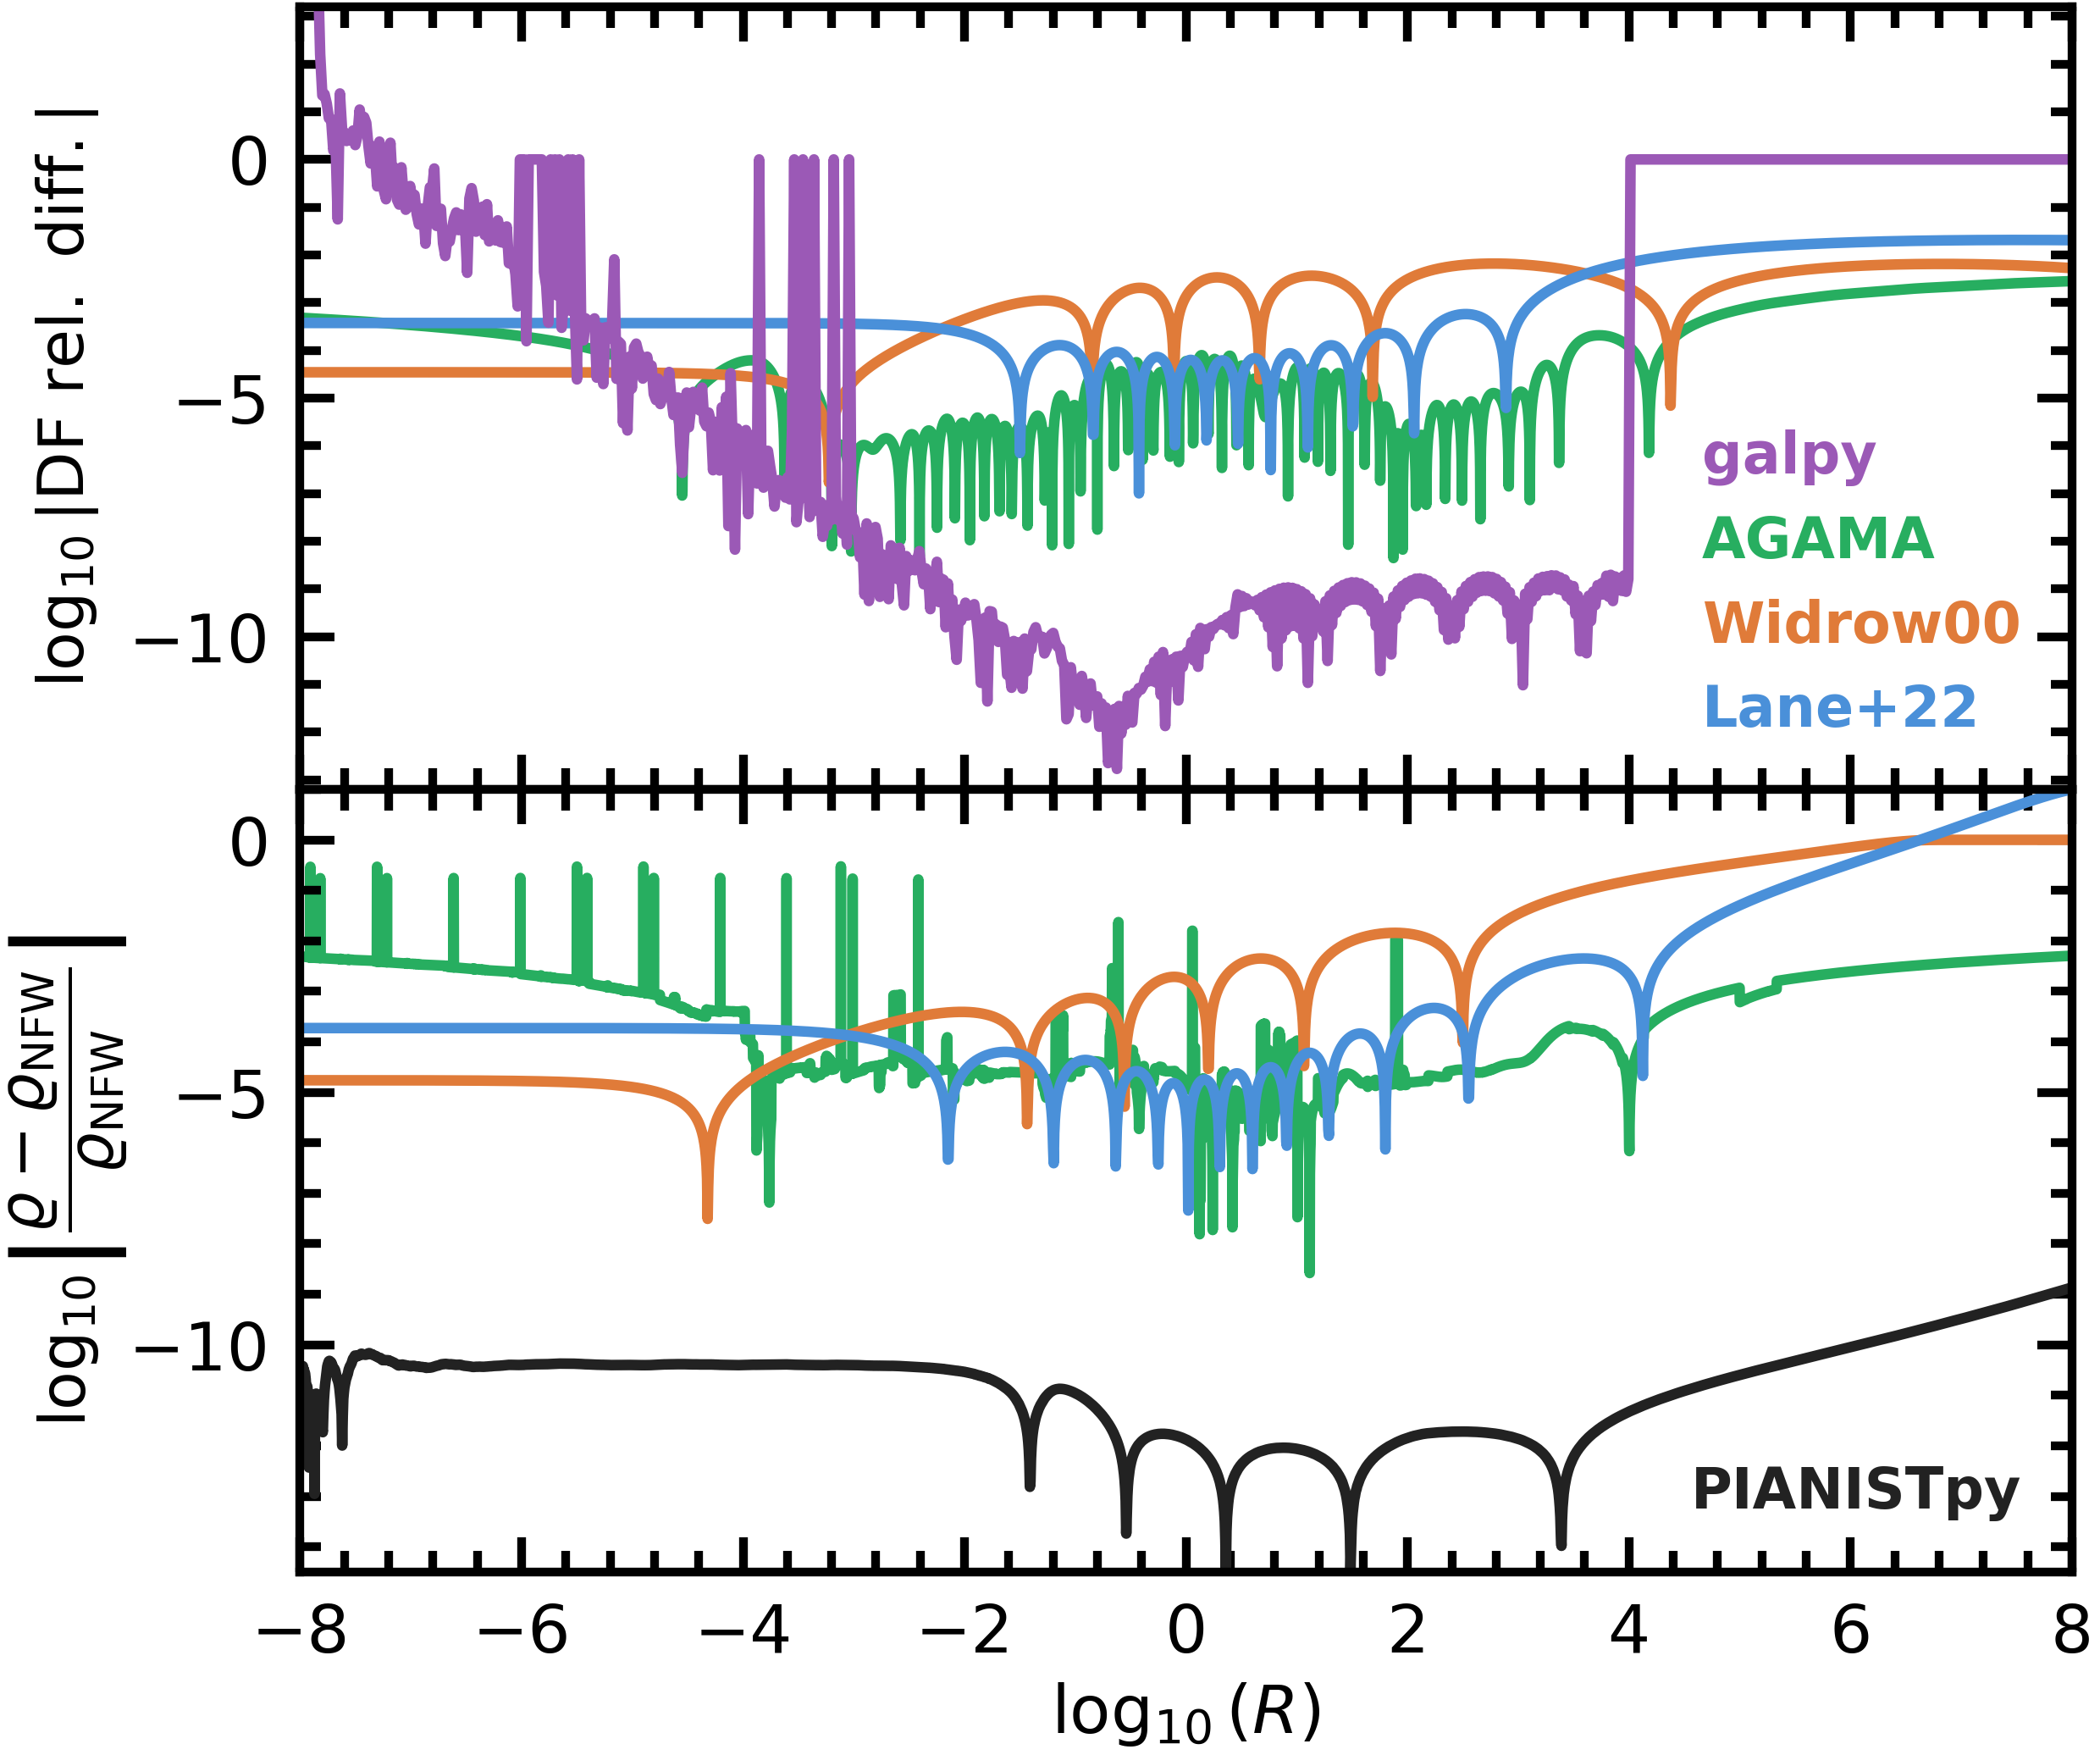

In [6]:
import os
import sys

import matplotlib
import matplotlib as mpl  # noqa: E402
import matplotlib.pyplot as plt  # noqa: E402
import matplotlib.ticker as ticker  # noqa: E402
import numpy as np  # noqa: E402
from matplotlib.font_manager import FontProperties  # noqa: E402
from matplotlib.lines import Line2D  # noqa: E402
from PIL import Image  # noqa: E402
from PIL.PngImagePlugin import PngInfo  # noqa: E402
from scipy.interpolate import CubicSpline  # noqa: E402

NPZ, EXT, OUTPUT_FIG = "fig08_curves.npz", ".", "NFW_Benchmark_Iso_chop.png"   # [1.0.0] the cells above
XMIN, XMAX = (-8, 8)     # to log R = 8 (the paper: 4.7)

COLOR_PIANIST = "#222222"
COLOR_WIDROW = "#e07b39"
COLOR_LANE = "#4a90d9"
COLOR_GALPY = "#9b59b6"
COLOR_AGAMA = "#27ae60"
FONTSIZE_AXIS_LABEL = 19
FONTSIZE_TICK_LABEL = 19
FONTSIZE_LEGEND = 16     # (the paper's script: 13)
FRAME_LINEWIDTH = 2.1
TICK_LINEWIDTH = 2.1
TICK_MAJOR_LENGTH = 10.0
TICK_MINOR_LENGTH = 6.0
DELTA_LINEWIDTH = 3.0
DELTA_DF_YMIN, DELTA_DF_YMAX = -13.2, 3.2       # the paper's -9.2 lowered by 4
DELTA_RHO_YMIN, DELTA_RHO_YMAX = -14.5, 1.0     # the paper's (-15.8, 0.3) set to (-14.5, 1)

z = np.load(NPZ)
logR = z["logR"]
Fp = z["pianist_F_at_Pnfw"]
dw = z["widrow_F_at_Pnfw"] / Fp - 1.0
dl = z["lane_F_at_Pnfw"] / Fp - 1.0
lgFp = CubicSpline(logR, np.log10(Fp))

galpy = np.loadtxt(f"{EXT}/galpy_numerical_iso.txt", skiprows=1)
agama = np.loadtxt(f"{EXT}/agama_numerical_iso.txt", skiprows=1)


def vs_pianist(R, F):
    lr = np.log10(R)
    ok = (lr >= logR[0]) & (lr <= logR[-1]) & np.isfinite(F)
    out = np.full(R.shape, np.nan)
    out[ok] = F[ok] / 10.0 ** lgFp(lr[ok]) - 1.0
    return out


galpy_df = vs_pianist(galpy[:, 0], galpy[:, 2])
agama_df = vs_pianist(agama[:, 0], agama[:, 2])
agama_rho = agama[:, 4]


def style_ax(ax):
    for spine in ax.spines.values():
        spine.set_linewidth(FRAME_LINEWIDTH)
    ax.tick_params(which="major", direction="in", length=TICK_MAJOR_LENGTH, width=TICK_LINEWIDTH, labelsize=FONTSIZE_TICK_LABEL,
                   top=True, bottom=True, left=True, right=True)
    ax.tick_params(which="minor", direction="in", length=TICK_MINOR_LENGTH, width=TICK_LINEWIDTH,
                   top=True, bottom=True, left=True, right=True)


def plot_signed_delta(ax, log_R, delta_frac, color, lw=DELTA_LINEWIDTH, label="", fallback_y=None, zorder=2, nan_is_gap=False):
    delta_frac = np.asarray(delta_frac, dtype=float)
    log_R = np.asarray(log_R, dtype=float)
    if nan_is_gap:
        # a NaN here is a radius with no value (outside a file's range, or past a fit's own potential zero), not a
        # numerical failure: left out rather than marked
        keep = np.isfinite(delta_frac)
        delta_frac, log_R = delta_frac[keep], log_R[keep]
    abs_d = np.abs(delta_frac)
    log_d = np.where((abs_d > 0) & np.isfinite(abs_d), np.log10(np.maximum(abs_d, 1e-300)), np.nan)
    fallback_mask = ~np.isfinite(delta_frac)
    if fallback_y is not None and np.any(fallback_mask):
        ax.scatter(log_R[fallback_mask], np.full(int(np.sum(fallback_mask)), fallback_y), color=color, marker="v", s=18, zorder=zorder)
    finite = np.isfinite(log_d)
    if np.any(finite):
        ax.plot(log_R[finite], log_d[finite], color=color, lw=lw, ls="-", label=label if label else None, zorder=zorder)


def _finite_log10abs(arr):
    a = np.abs(np.asarray(arr, dtype=float))
    v = a[(a > 0) & np.isfinite(a)]
    return np.log10(v) if len(v) > 0 else np.array([0.0])


fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(9, 8), sharex=True, gridspec_kw={"hspace": 0.0, "height_ratios": [1.0, 1.0]})
_df_ymax = float(np.max(np.concatenate([_finite_log10abs(dw), _finite_log10abs(dl), _finite_log10abs(galpy_df),
                                        _finite_log10abs(agama_df)]))) + 0.5
_rho_ymax = float(np.max(np.concatenate([_finite_log10abs(z["pianist_rt"]), _finite_log10abs(z["widrow_rt"]),
                                         _finite_log10abs(z["lane_rt"]), _finite_log10abs(agama_rho)]))) + 0.5

plot_signed_delta(ax_top, np.log10(agama[:, 0]), agama_df, COLOR_AGAMA, label="AGAMA", fallback_y=_df_ymax, zorder=1, nan_is_gap=True)
plot_signed_delta(ax_top, logR, dw, COLOR_WIDROW, label="Widrow", fallback_y=_df_ymax, zorder=2, nan_is_gap=True)
plot_signed_delta(ax_top, logR, dl, COLOR_LANE, label="Lane+", fallback_y=_df_ymax, zorder=2, nan_is_gap=True)
plot_signed_delta(ax_top, np.log10(galpy[:, 0]), galpy_df, COLOR_GALPY, label="galpy", fallback_y=_df_ymax, zorder=2, nan_is_gap=True)
ax_top.set_ylim(DELTA_DF_YMIN, DELTA_DF_YMAX)
ax_top.set_xlim(XMIN, XMAX)
style_ax(ax_top)
plt.setp(ax_top.get_xticklabels(), visible=False)

plot_signed_delta(ax_bot, np.log10(agama[:, 0]), agama_rho, COLOR_AGAMA, label="AGAMA", fallback_y=_rho_ymax, zorder=1)
plot_signed_delta(ax_bot, logR, z["pianist_rt"], COLOR_PIANIST, label="PIANISTpy", fallback_y=_rho_ymax, zorder=2, nan_is_gap=True)
# the Widrow DF's self-consistent potential reaches zero at R = 7.09e6 (the curve cell: P = 1e-11 there): the model ends, its density beyond
# is zero and the relative error exactly -1 (the legacy script likewise read 0 density past a fit's ODE range)
_w = np.array(z["widrow_rt"], dtype=float)
_w[np.arange(_w.size) > np.flatnonzero(np.isfinite(_w))[-1]] = -1.0
plot_signed_delta(ax_bot, logR, _w, COLOR_WIDROW, label="Widrow", fallback_y=_rho_ymax, zorder=2, nan_is_gap=True)
plot_signed_delta(ax_bot, logR, z["lane_rt"], COLOR_LANE, label="Lane+", fallback_y=_rho_ymax, zorder=2, nan_is_gap=True)
with mpl.rc_context({"mathtext.fontset": "cm"}):
    ax_bot.set_ylabel(r"$\log_{10}\!\left|\dfrac{\varrho - \varrho_{\rm NFW}}{\varrho_{\rm NFW}}\right|$",
                      fontsize=FONTSIZE_AXIS_LABEL - 1, labelpad=0)
mpl.rcParams["mathtext.fontset"] = "dejavusans"
ax_bot.set_xlabel(r"$\log_{10}(R)$", fontsize=FONTSIZE_AXIS_LABEL, labelpad=4)
ax_top.set_ylabel(r"$\log_{10}|{\rm DF\ rel.\ diff.}|$", fontsize=FONTSIZE_AXIS_LABEL - 1, labelpad=8)
ax_bot.set_ylim(DELTA_RHO_YMIN, DELTA_RHO_YMAX)
ax_bot.set_xlim(XMIN, XMAX)
style_ax(ax_bot)

_bold_fp = FontProperties(weight="bold", size=FONTSIZE_LEGEND)


def text_legend(ax, names, colors, loc):
    """a text-only legend (no line handles), each entry bold in its curve's color"""
    lg = ax.legend(handles=[Line2D([], [], color="none", label=n) for n in names], fontsize=FONTSIZE_LEGEND, frameon=False, loc=loc,
                   handlelength=0, handletextpad=0, prop=_bold_fp)
    for t, c in zip(lg.get_texts(), colors):
        t.set_color(c)
        t.set_fontproperties(_bold_fp)
    return lg


# the four codes of both panels at the top panel's lower right; PIANISTpy, drawn only in the bottom panel,
# alone at the bottom panel's lower right
text_legend(ax_top, ["galpy", "AGAMA", "Widrow00", "Lane+22"], [COLOR_GALPY, COLOR_AGAMA, COLOR_WIDROW, COLOR_LANE], "lower right")
text_legend(ax_bot, ["PIANISTpy"], [COLOR_PIANIST], "lower right")
for ax in (ax_top, ax_bot):
    ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
    ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

import os as _fs_os, sys as _fs_sys
_fs_sys.path.insert(0, 'scripts')
import print_frame_fs as _fs_pf  # frames and ticks at their printed size
_fs_s = _fs_pf.apply(fig, f=1.0, slot='column', width_pt=float(_fs_os.environ.get('PRINT_WIDTH_PT', 590.2)))
print(f'printed scale s = {_fs_s:.4f} (f 1.0, slot column, W_fig {_fs_os.environ.get("PRINT_WIDTH_PT", 590.2)} pt)', flush=True)
fig.savefig(OUTPUT_FIG, bbox_inches="tight", dpi=300)
plt.close(fig)
meta = PngInfo()
meta.add_text("Title", "Benchmark of the isotropic NFW distribution function")
meta.add_text("PIANISTpy product", "compute_df of pianistpy 1.0.0")  # [1.0.0]
meta.add_text("Source", "fig08_curves.npz (PIANISTpy, Widrow 2000, Lane et al. 2022: forward density and Poisson solve); "
              "galpy_numerical_iso.txt and agama_numerical_iso.txt")
pixel_crop = 22
with Image.open(OUTPUT_FIG) as img:
    width, height = img.size
    img.crop((pixel_crop, pixel_crop, width - pixel_crop, height - pixel_crop)).save(OUTPUT_FIG, pnginfo=meta)
print(f"{OUTPUT_FIG}: x [{XMIN}, {XMAX}]")
for name, arr, lr in (("PIANISTpy rt", z["pianist_rt"], logR), ("Widrow rt", z["widrow_rt"], logR), ("Lane rt", z["lane_rt"], logR),
                      ("agama rho", agama_rho, np.log10(agama[:, 0]))):
    a = np.log10(np.abs(arr[(lr >= XMIN) & (lr <= XMAX) & np.isfinite(arr) & (arr != 0)]))
    print(f"  {name}: log10|delta| over [{a.min():.2f}, {a.max():.2f}] (axis [{DELTA_RHO_YMIN}, {DELTA_RHO_YMAX}])")

from IPython.display import Image as _Img, display as _display  # [1.0.0] the PNG inline
_display(_Img(OUTPUT_FIG))
